# Poisson

Lecture 2 (16/11) - Distributions

## Exercise

1. Generate $n = 10$ uniformly distributed values of $t$ in interval $[0, \Delta t = 10^3]$.
2. Compute number of accepted events $k$ that happen in interval $[0, \delta t]$ with $\delta t = p \cdot \Delta t$ and $p = 0.01$.
3. Repeat $10^5$ times, and populate histogram of $k$.
4. Plot histogram of $k$ and compare with theoretical Binomial and Poisson distribution. **Do not use any predefined method!**
5. Repeat for all combinations of:
   - $n = 10,\ 100,\ 1000$
   - $p = 0.01,\ 0.05,\ 0.1,\ 0.5$

   to see who is the best.

**Note:** we have to normalize.

## Solution

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson

from numpy.random import uniform

### Functions

In [28]:
def simulate_counts(n, p, n_rep, T, rng):
    """k = number of n uniform points in [0, p*T], repeated n_rep times."""
    k = np.empty(n_rep, dtype=int)
    for start in range(0, n_rep):          
        t = rng.uniform(0, T, n)
        k[start] = (t < p * T).sum()
    return k

def binom_log(k, n, p):
    # ln(m!) = sum_{i=2}^{m} ln i, for m = 0..n
    #ln_fact = np.concatenate(([0.0], np.cumsum(np.log(np.arange(1, n + 1)))))
    ld = np.longdouble
    ln_fact = np.concatenate(([ld(0)], np.cumsum(np.log(np.arange(1, n + 1, dtype=ld)))))
    ln_coef = ln_fact[n] - ln_fact[k] - ln_fact[n - k]   # ln C(n,k)
    return np.exp(ln_coef + k * np.log(p) + (n - k) * np.log(1 - p))

def poisson_log(k, mu):
    # P(k; mu) = mu^k e^{-mu} / k!   ->   ln P = k ln(mu) - mu - ln(k!)
    # ln(m!) = sum_{i=1}^{m} ln i, for m = 0..k_max
    ld = np.longdouble
    k = np.asarray(k)
    k_max = int(k.max())
    ln_fact = np.concatenate(([ld(0)], np.cumsum(np.log(np.arange(1, k_max + 1, dtype=ld)))))
    return np.exp(k * np.log(ld(mu)) - ld(mu) - ln_fact[k])


### Plots

In [7]:
# Data
T = 1e3
n_rep = 10**5

ns = [10, 100, 1000]
ps = [0.01, 0.05, 0.1, 0.5]
rng = np.random.default_rng(12345)

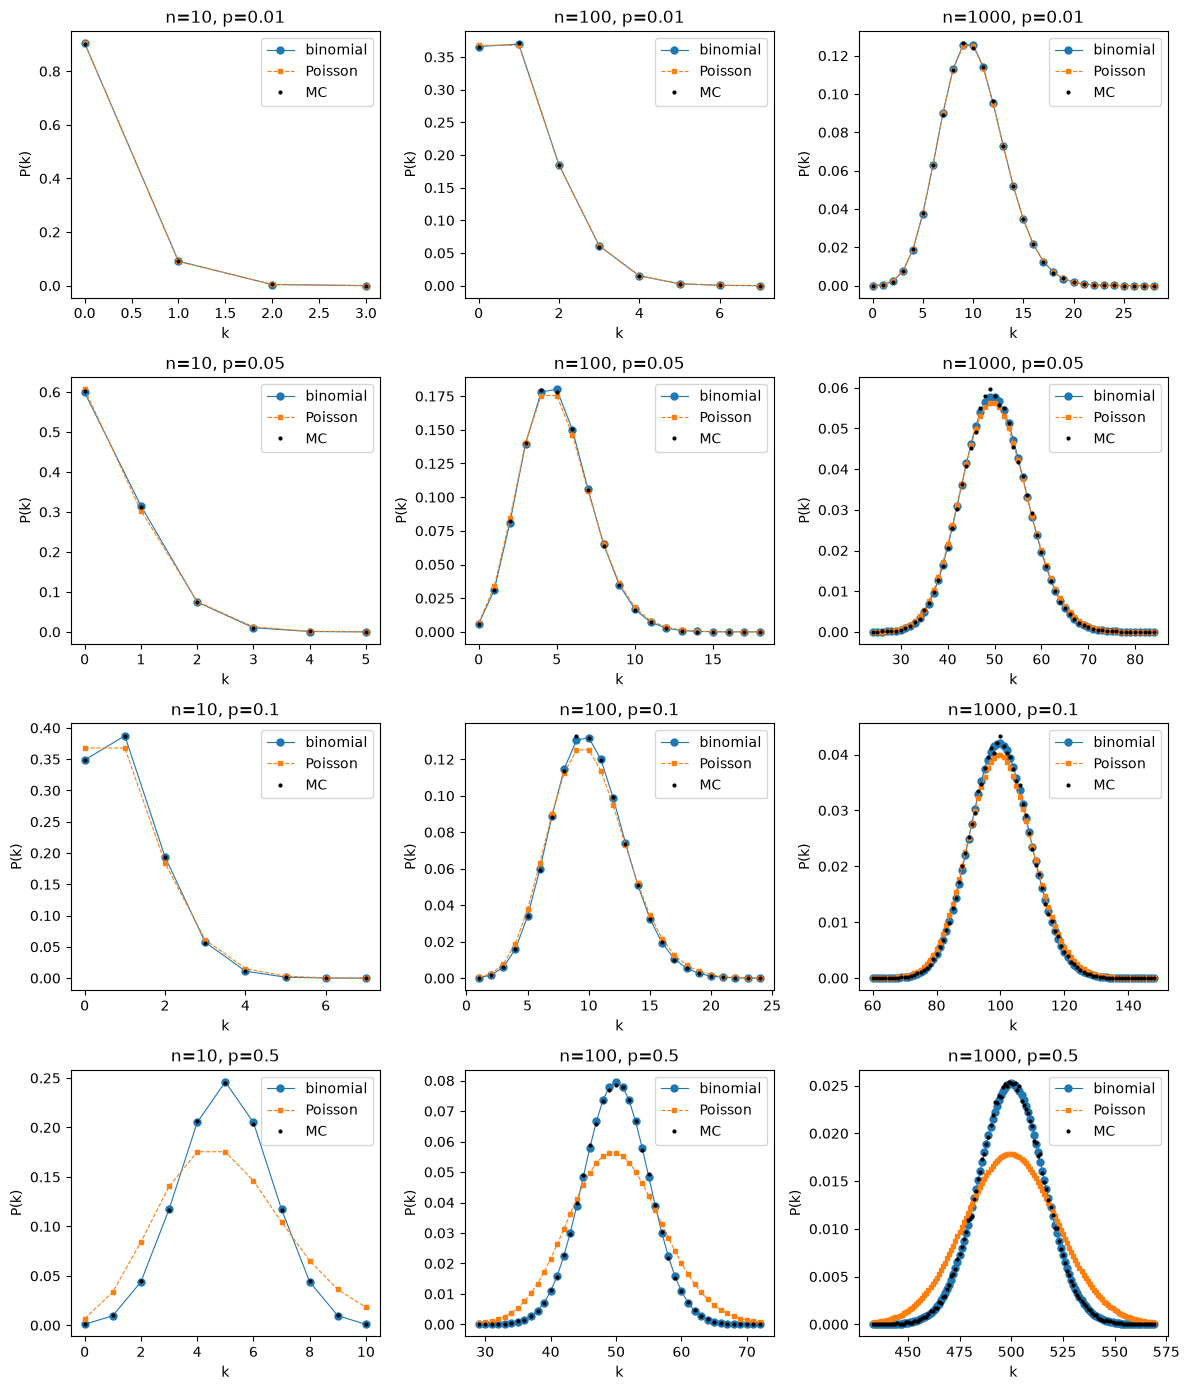

In [29]:
fig, axes = plt.subplots(len(ps), len(ns), figsize=(12, 14))

for i, p in enumerate(ps):
    for j, n in enumerate(ns):
        k_all = simulate_counts(n, p, n_rep, T, rng)
        k = np.arange(k_all.min(), k_all.max() + 1)
        counts = np.bincount(k_all, minlength=k_all.max() + 1)[k]

        pb = binom_log(k, n, p)
        pp = poisson_log(k, n * p)

        ax = axes[i, j]
        ax.plot(k, pb, "-o", ms=5, lw=0.8, label="binomial")
        ax.plot(k, pp, "--s", ms=3, lw=0.8, label="Poisson")
        ax.plot(k, counts / n_rep, "o", ms=2, c="k", label="MC")
        ax.set_title(f"n={n}, p={p}")
        ax.set_xlabel("k"); ax.set_ylabel("P(k)")
        ax.legend()


fig.tight_layout()
plt.show()

## Conclusions

- **Binomial.** It describes all 12 $(n,p)$ combinations. This is expected, since $k$ is binomial by
  construction.
- **Poisson.** It is a good description only for small $p$. For $p=0.5$ it is
  completely off: its variance $np$ is larger than the
  binomial one, $np(1-p)$, so the Poisson curve is too wide.
- **What matters is $p$, not $n$.** The ratio of the two variances is $1-p$,
  independent of $n$. Increasing $n$ does not help unless $p$ is also small
  (limit $p\to0$, $np$ fixed).
- **Small $p$.** For $p=0.01$ the two distributions are almost
  indistinguishable with $10^5$ repetitions. Here the Poisson is a perfectly good
  and simpler approximation.
- **Best description.** The binomial, always. The Poisson is a valid
  approximation when $p\lesssim0.05$, with a sizeable discrepancy already
  at $p=0.1$.
